# Diễn giải ensemble C30 cho mục 4.7

Giữ mô hình RF 25% + XGBoost 25% + ExtraTrees 50% và tham số đã chốt. Phân tích trên validation; không dùng test hoặc dữ liệu demo mới.

Permutation importance đo mức tăng MAE khi xáo trộn đầu vào của mô hình đã fit. Đo ba nhóm trước, sau đó khảo sát riêng ba cột history. Đây là phân tích thăm dò vì validation đã được xem nhiều lần; kết quả không dùng để chọn lại mô hình.


## 1. Đọc cấu hình và đặt seed

Tìm thư mục dự án từ vị trí notebook. Tham số và trọng số đọc trực tiếp từ đặc tả đã khóa. Kết quả mới được lưu riêng trong `outputs/interpretation_C30`.


In [1]:
from pathlib import Path
import hashlib, json, platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, Image
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/feature_experiments.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src import feature_experiments as fe
from src.features import CONFIG_A, CONFIG_B, CONFIG_C, HISTORY_FEATURES, add_time_features, add_weather_features, add_history_features, has_history
from src.preprocessing import fit_weather_fill
from src.evaluation import regression_metrics

SEED, REPEATS = 42, 20
OUT = ROOT / 'notebooks/validation/outputs/interpretation_C30'
OUT.mkdir(parents=True, exist_ok=True)
spec_path = ROOT / 'notebooks/validation/outputs/final_C30/selected_model.json'
spec = json.loads(spec_path.read_text(encoding='utf-8'))
features = list(CONFIG_C)
assert features == spec['features']


## 2. Chuẩn bị đúng train và validation

Chỉ đọc giá trị dữ liệu đến hết validation; số dòng tổng dùng để xác định ranh giới 70/15/15. Tạo history trước khi lọc cohort để giữ các quan sát quá khứ. `prepare_fold` học cách điền thiếu từ cohort train và tạo ma trận giống thí nghiệm đã chốt.


In [2]:
data_path = ROOT / 'data/preprocessed/hourly_unfilled.csv'
n_total = len(pd.read_csv(data_path, usecols=['date_time']))
train_stop, valid_stop = n_total * 70 // 100, n_total * 85 // 100
hourly = pd.read_csv(data_path, nrows=valid_stop, keep_default_na=False,
                     na_values={'temp': [''], 'rain_1h': ['']}, float_precision='round_trip')
hourly['date_time'] = pd.to_datetime(hourly.date_time)
featured = add_history_features(add_weather_features(add_time_features(hourly)))
train = featured.iloc[:train_stop].loc[lambda d: has_history(d)].copy()
valid = featured.iloc[train_stop:].loc[lambda d: has_history(d)].copy()
assert len(train) == spec['current_validation_fit_n'] and len(valid) == spec['validation_n']
x_train, x_valid, fill_log = fe.prepare_fold(hourly, featured, train.date_time, valid.date_time)
X_train = np.ascontiguousarray(x_train[features], dtype='float32')
X_valid = np.ascontiguousarray(x_valid[features], dtype='float32')
y_train, y_valid = train.traffic_volume.to_numpy(), valid.traffic_volume.to_numpy()
display(pd.DataFrame([{'scope': name, 'n': len(part), 'start': part.date_time.min(), 'end': part.date_time.max()}
                      for name, part in [('train cohort', train), ('validation cohort', valid)]]))

source_run = json.loads((ROOT / 'experiments/20-11-2026_Huy_C30_Params1/outputs/run_config.json').read_text(encoding='utf-8'))
for key in ['fit_matrix_hash', 'score_matrix_hash']:
    assert fill_log[key] == source_run['preprocessing'][key], key


               scope      n               start                 end
0       train cohort  22503 2012-10-09 09:00:00 2017-05-10 04:00:00
1  validation cohort   6050 2017-05-10 05:00:00 2018-01-19 14:00:00

## 3. Fit lại cấu hình đã chốt

Chỉ fit trên train, giữ nguyên mọi tham số. Mỗi mô hình dự đoán rồi cắt phần âm về 0; ensemble lấy trung bình theo trọng số đã khóa. Không thực hiện tìm kiếm tham số.

RF/XGBoost trong lượt gốc được fit với giới hạn threadpool bằng 1; notebook giữ cách chạy này để tái lập. ExtraTrees giữ cách chạy gốc của lượt bổ sung.


In [3]:
constructors = {'Random Forest': RandomForestRegressor, 'XGBoost': XGBRegressor, 'ExtraTrees': ExtraTreesRegressor}
models = {}
for name, constructor in constructors.items():
    params = spec['components'][name]['params'].copy()
    if name == 'XGBoost':
        params.pop('missing', None)  # Dùng NaN mặc định, không truyền sentinel dạng chuỗi.
    with threadpool_limits(limits=1 if name != 'ExtraTrees' else None):
        models[name] = constructor(**params).fit(X_train, y_train)
    print(f'Đã fit {name}.', flush=True)

def predict_ensemble(matrix):
    parts = [spec['weights'][name] * np.clip(model.predict(matrix), 0, None).astype('float64')
             for name, model in models.items()]
    return np.clip(np.sum(parts, axis=0), 0, None)


Đã fit Random Forest.
Đã fit XGBoost.
Đã fit ExtraTrees.


## 4. Tái lập kết quả trước khi giải thích

So từng timestamp, target và dự đoán với file đã lưu. Nếu sai khác vượt dung sai, notebook dừng để kiểm tra thay vì tiếp tục xuất importance. Artifact lưu ở đây chỉ fit trên train để giải thích validation, chưa phải mô hình refit trên train + validation.


In [4]:
prediction = predict_ensemble(X_valid)
reference_path = ROOT / 'experiments/22-11-2026_Huy_C30_MAE_Diversity/outputs/validation_predictions.csv'
reference = pd.read_csv(reference_path, parse_dates=['date_time'], float_precision='round_trip')
np.testing.assert_array_equal(valid.date_time.to_numpy(), reference.date_time.to_numpy())
np.testing.assert_array_equal(y_valid, reference.y_true.to_numpy())
component_predictions = pd.DataFrame({name: model.predict(X_valid) for name, model in models.items()})
component_predictions.to_csv(OUT / 'component_predictions.csv', index=False)
np.testing.assert_allclose(prediction, reference['Selected by OOF'], rtol=0, atol=1e-5)
base = regression_metrics(y_valid, prediction)
assert np.isclose(base['MAE'], spec['validation_metrics']['MAE'], rtol=0, atol=1e-6)
pd.DataFrame([{'model': spec['model_id'], 'n': len(valid), **base}]).to_csv(OUT / 'baseline_metrics.csv', index=False)
pd.DataFrame({'date_time': valid.date_time.to_numpy(), 'y_true': y_valid, 'prediction': prediction}).to_csv(OUT / 'validation_predictions.csv', index=False)
joblib.dump({'scope': 'train-only fit for validation interpretation', 'models': models, 'spec': spec,
             'features': features, 'fill_statistics': fit_weather_fill(hourly.set_index('date_time', drop=False).loc[train.date_time]),
             'train_end': str(train.date_time.max())}, OUT / 'train_C30_interpretation.joblib', compress=3)
display(Markdown(f'Tái lập đúng **{len(valid):,} giờ validation**: MAE **{base["MAE"]:.4f} xe/giờ**. Có thể tiếp tục phân tích.'))


Tái lập đúng **6.050 giờ validation**: MAE **190.1900 xe/giờ**. Có thể tiếp tục phân tích.

## 5. Xáo trộn nhóm và từng cột history

Đo ba nhóm Time, Weather, History; sau đó khảo sát ba lag/mean riêng. Các cột trong một nhóm cùng nhận một hoán vị để giữ quan hệ nội bộ. Dùng lại cùng 20 hoán vị giữa các phép đo, giữ nguyên target và mô hình. ΔMAE = MAE sau xáo trộn − MAE gốc.

Xáo trộn làm mất quan hệ theo thời gian và có thể tạo tổ hợp đầu vào ít gặp. Phép đo mô tả mức phụ thuộc của mô hình trên validation, không phải mô phỏng triển khai hay bằng chứng nhân quả.


In [5]:
groups = {'Time': list(CONFIG_A), 'Weather': [f for f in CONFIG_B if f not in CONFIG_A], 'History': list(HISTORY_FEATURES)}
checks = [('group', name, cols) for name, cols in groups.items()]
checks += [('history', name, [name]) for name in HISTORY_FEATURES]
permutations = [np.random.default_rng(SEED + repeat).permutation(len(valid)) for repeat in range(REPEATS)]
rows = []
for kind, name, columns in checks:
    positions = [features.index(col) for col in columns]
    for repeat, order in enumerate(permutations, 1):
        changed = X_valid.copy()
        changed[:, positions] = X_valid[order][:, positions]
        mae = np.abs(y_valid - predict_ensemble(changed)).mean()
        rows.append({'kind': kind, 'feature': name, 'repeat': repeat, 'n': len(valid),
                     'n_columns': len(columns), 'MAE_shuffled': mae, 'delta_MAE': mae - base['MAE']})
    print(f'Đã đo {name}: {REPEATS} lần.', flush=True)
runs = pd.DataFrame(rows)
runs.to_csv(OUT / 'permutation_runs.csv', index=False)
summary = runs.groupby(['kind', 'feature'], sort=False).agg(
    n=('n', 'first'), n_columns=('n_columns', 'first'), repeats=('repeat', 'size'),
    delta_MAE_mean=('delta_MAE', 'mean'), delta_MAE_std=('delta_MAE', 'std')).reset_index()
for kind, filename in [('group', 'group_importance.csv'), ('history', 'history_importance.csv')]:
    summary.loc[summary.kind.eq(kind)].sort_values('delta_MAE_mean', ascending=False).to_csv(OUT / filename, index=False)
display(summary.round(3))


Đã đo Time: 20 lần.
Đã đo Weather: 20 lần.
Đã đo History: 20 lần.
Đã đo lag_24h: 20 lần.
Đã đo lag_168h: 20 lần.
Đã đo mean_24h: 20 lần.


      kind   feature     n  n_columns  repeats  delta_MAE_mean  delta_MAE_std
0    group      Time  6050         12       20        1150.005         12.112
1    group   Weather  6050         15       20           8.441          0.716
2    group   History  6050          3       20         819.397          7.836
3  history   lag_24h  6050          1       20         231.959          2.744
4  history  lag_168h  6050          1       20         404.616          5.455
5  history  mean_24h  6050          1       20         110.938          1.663

## 6. Vẽ hình và nhận xét

Thanh dài hơn cho biết MAE tăng nhiều hơn khi đầu vào bị xáo trộn. Thanh sai số là SD giữa 20 lần hoán vị, không phải khoảng tin cậy thống kê. Không cộng importance của các lag riêng để suy ra importance cả nhóm vì các đặc trưng có thể chia sẻ thông tin.


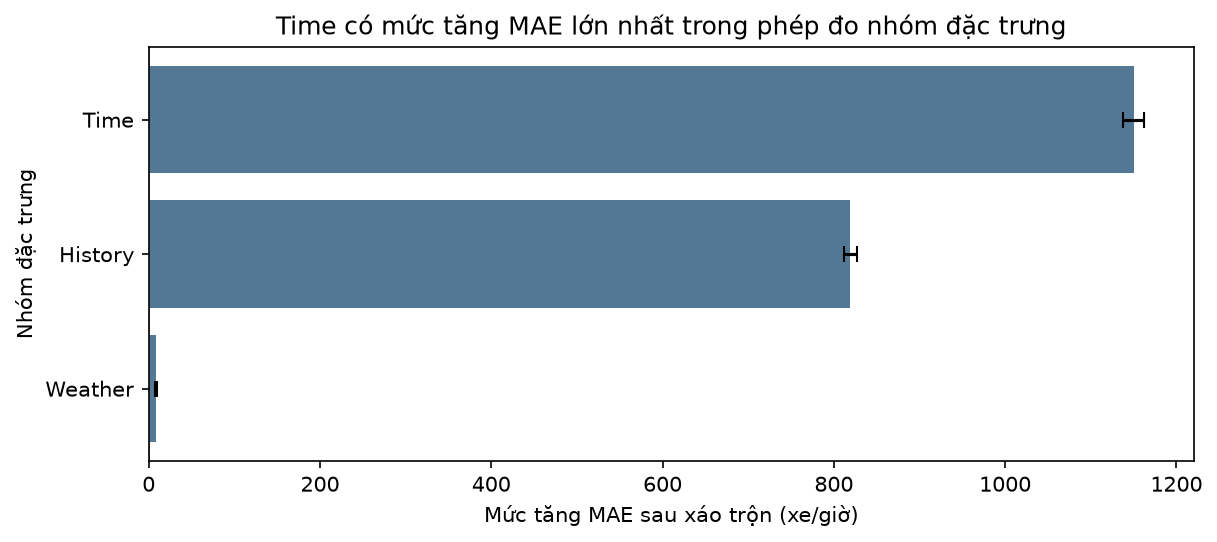

Đọc biểu đồ này như sau: xáo trộn Time làm MAE tăng trung bình 1150.01 xe/giờ, SD 12.11, trên 6,050 giờ. Đây là mức phụ thuộc của mô hình trong phép đo; chưa chứng minh đặc trưng có tác động nhân quả.

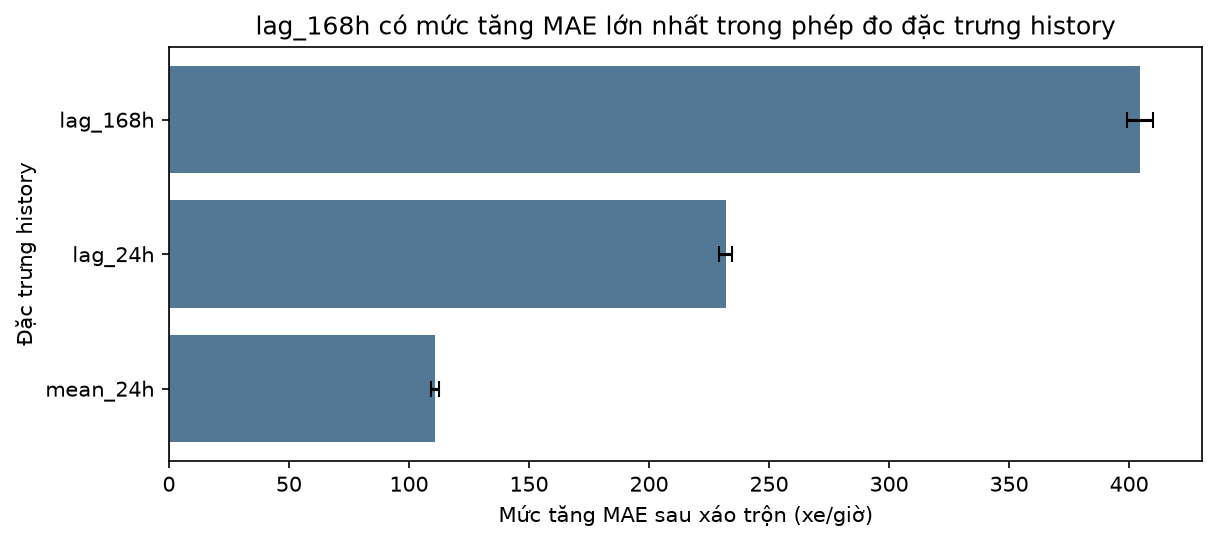

Đọc biểu đồ này như sau: xáo trộn lag_168h làm MAE tăng trung bình 404.62 xe/giờ, SD 5.45, trên 6,050 giờ. Đây là mức phụ thuộc của mô hình trong phép đo; chưa chứng minh đặc trưng có tác động nhân quả.

Các đặc trưng tương quan có thể chia sẻ thông tin, nên importance nhỏ chưa đủ để bỏ cột. Validation đã được xem nhiều lần; kết quả có tính thăm dò. Giữ cấu hình đã chốt, không dùng test để phân tích.

In [8]:
notes = []
for kind, label in [('group', 'nhóm đặc trưng'), ('history', 'đặc trưng history')]:
    table = summary.loc[summary.kind.eq(kind)].sort_values('delta_MAE_mean')
    top = table.iloc[-1]
    fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
    ax.barh(table.feature, table.delta_MAE_mean, xerr=table.delta_MAE_std, color='#537895', capsize=4)
    ax.axvline(0, color='gray', linewidth=0.8)
    ax.set(xlabel='Mức tăng MAE sau xáo trộn (xe/giờ)', ylabel=label.capitalize(),
           title=f'{top.feature} có mức tăng MAE lớn nhất trong phép đo {label}')
    fig.savefig(OUT / f'interpretation_C30_{kind}.png', dpi=150, bbox_inches='tight')
    display(Image(filename=str(OUT / f'interpretation_C30_{kind}.png')))
    plt.close(fig)
    note = (f'Đọc biểu đồ này như sau: xáo trộn {top.feature} làm MAE tăng trung bình '
            f'{top.delta_MAE_mean:.2f} xe/giờ, SD {top.delta_MAE_std:.2f}, trên {int(top.n):,} giờ. '
            'Đây là mức phụ thuộc của mô hình trong phép đo; chưa chứng minh đặc trưng có tác động nhân quả.')
    display(Markdown(note))
    notes.append(note)
limitations = ('Các đặc trưng tương quan có thể chia sẻ thông tin, nên importance nhỏ chưa đủ để bỏ cột. '
              'Validation đã được xem nhiều lần; kết quả có tính thăm dò. Giữ cấu hình đã chốt, không dùng test để phân tích.')
display(Markdown(limitations))
_ = (OUT / 'observations.md').write_text('\n\n'.join(notes + [limitations]), encoding='utf-8')


## 7. Lưu thông tin tái lập

Lưu seed, số lần xáo trộn, nhóm cột và hash nguồn. Kết quả dùng cho mục 4.7; đối chứng FE ở mục 4.8 vẫn là thí nghiệm huấn luyện các cấu hình khác nhau.


In [7]:
record = {'model_id': spec['model_id'], 'scope': 'validation interpretation; train-only fit',
          'n_train': len(train), 'n_validation': len(valid), 'seed': SEED, 'n_repeats': REPEATS,
          'groups': groups, 'history_columns': list(HISTORY_FEATURES), 'baseline': base,
          'max_prediction_difference': float(np.max(np.abs(prediction - reference['Selected by OOF'].to_numpy()))),
          'thread_policy': 'RF/XGB fit under threadpool_limits(1), ExtraTrees unchanged',
          'test_evaluated': False, 'retuned': False, 'validation_previously_seen': True,
          'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                       'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__},
          'source_sha256': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                            for p in [spec_path, data_path, reference_path]},
          'preprocessing': fill_log,
          'reading': 'SD describes permutation variation; not statistical confidence or causal importance.'}
(OUT / 'analysis_record.json').write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu bảng, hình, nhận xét và artifact tại:', OUT)


Đã lưu bảng, hình, nhận xét và artifact tại: E:\Project\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\notebooks\validation\outputs\interpretation_C30
